# Sumativa 1 · Carga de datos y reporte de calidad

Carga **Rain in Australia**, verifica su estructura, documenta faltantes, duplicados, inconsistencias y valores extremos, y fija el tratamiento de cada caso. Las funciones están en `src/calidad.py` para que los demás análisis partan de los mismos datos. El problema de estudio es anticipar la lluvia del día siguiente (`RainTomorrow`).

## 1. Carga y verificación del archivo fuente (raw)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

raiz = next(c for c in (Path.cwd(), *Path.cwd().parents) if (c / "src" / "calidad.py").is_file())
sys.path.insert(0, str(raiz))
from src import calidad

SEMILLA = 42  # semilla del grupo; este cuaderno no usa muestreo aleatorio
pd.set_option("display.max_rows", 60)

datos = calidad.cargar_datos()  # detiene la ejecución si el SHA-256 no coincide
print("SHA-256 verificado:", calidad.SHA256_RAW)
print(f"Filas: {len(datos)} | Columnas: {datos.shape[1]}")
print(f"Periodo: {datos['Date'].min():%Y-%m-%d} a {datos['Date'].max():%Y-%m-%d}")
print(f"Ubicaciones: {datos['Location'].nunique()}")

SHA-256 verificado: 573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014
Filas: 145460 | Columnas: 23
Periodo: 2007-11-01 a 2017-06-25
Ubicaciones: 49


## 2. Estructura y tipos de variables

La carga convierte `Date` a fecha y declara como categóricas la ubicación, las direcciones del viento (16 rumbos) y los dos indicadores de lluvia. Es la única transformación aplicada.

In [2]:
estructura = calidad.clasificacion_variables().loc[datos.columns]
estructura.insert(0, "Tipo en pandas", datos.dtypes.astype(str))
display(estructura)
display(estructura["Tipo"].value_counts().to_frame("Variables"))

,Tipo en pandas,Tipo,Escala,Unidad
Variable,,,,
Date,datetime64[us],Fecha,Intervalo,día
Location,category,Cualitativa nominal,Nominal,ubicación
MinTemp,float64,Cuantitativa continua,Intervalo,°C
MaxTemp,float64,Cuantitativa continua,Intervalo,°C
Rainfall,float64,Cuantitativa continua,Razón,mm
Evaporation,float64,Cuantitativa continua,Razón,mm
Sunshine,float64,Cuantitativa continua,Razón,horas
WindGustDir,category,Cualitativa nominal,Nominal circular,16 rumbos
WindGustSpeed,float64,Cuantitativa continua,Razón,km/h


,Variables
Tipo,
Cuantitativa continua,14
Cualitativa nominal,4
Cuantitativa discreta,2
Fecha,1
Cualitativa binaria,1
Cualitativa binaria (objetivo),1


Hay 16 variables numéricas (14 continuas y 2 discretas), 6 categóricas y 1 fecha. La presión se mide en hPa, con cero absoluto, por lo que es una escala de **razón**; las temperaturas en °C son de intervalo. La nubosidad se registra en oktas (0 a 8) y el código 9 indica cielo oscurecido.

## 3. Datos faltantes

,Faltantes,%
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


Filas sin ningún faltante: 56420 (38.79 %)


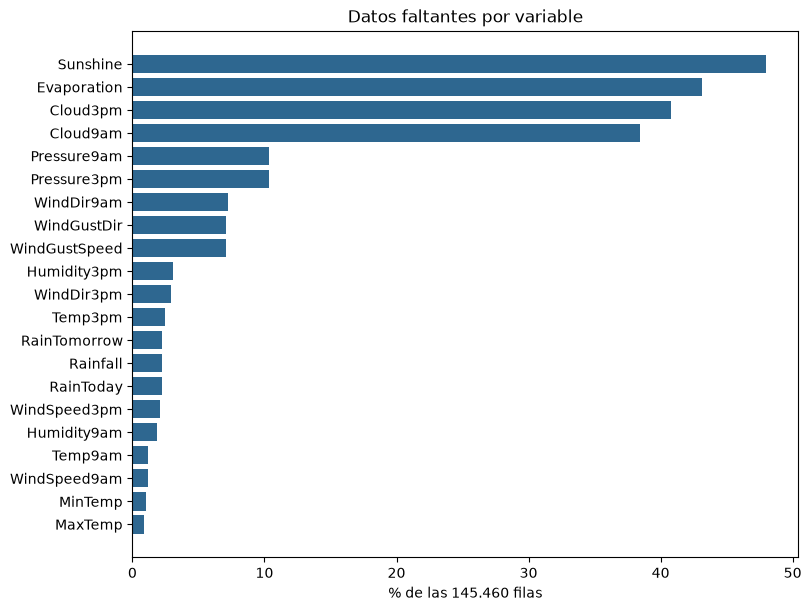

In [3]:
faltantes = pd.DataFrame({"Faltantes": datos.isna().sum(), "%": datos.isna().mean() * 100})
faltantes = faltantes.sort_values("%", ascending=False)
display(faltantes.round(2))
completas = len(datos.dropna())
print(f"Filas sin ningún faltante: {completas} ({100 * completas / len(datos):.2f} %)")

visibles = faltantes[faltantes["%"] > 0].sort_values("%")
fig, eje = plt.subplots(figsize=(8, 6), layout="constrained")
eje.barh(visibles.index, visibles["%"], color="#2E6790")
eje.set(title="Datos faltantes por variable", xlabel="% de las 145.460 filas")
plt.show()

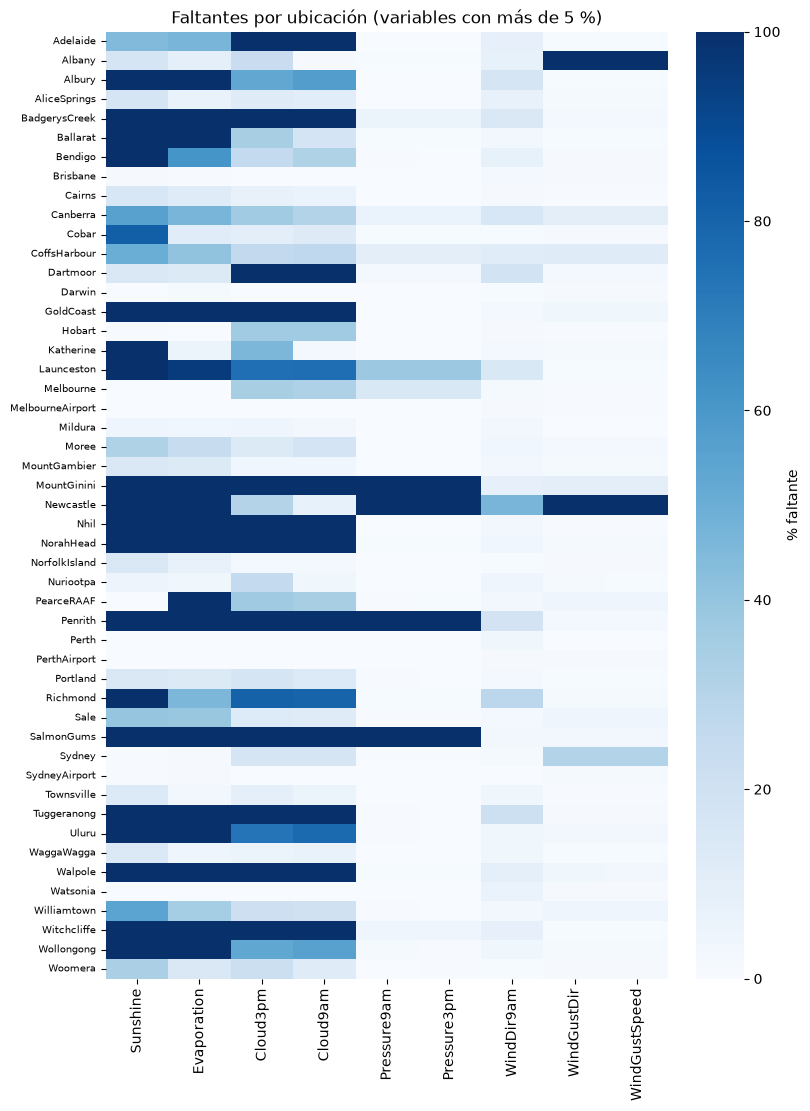

,Ubicaciones sin ningún registro,Faltantes,% de los faltantes que explican
Variable,,,
Sunshine,19,69835,76.1
Evaporation,16,62790,72.5
Cloud3pm,12,59358,58.9
Cloud9am,12,55888,62.6
Pressure9am,4,15065,80.4
Pressure3pm,4,15028,80.6


In [4]:
por_ubicacion = calidad.faltantes_por_ubicacion(datos)
orden = faltantes.index[faltantes["%"] > 5]
fig, eje = plt.subplots(figsize=(8, 11), layout="constrained")
sns.heatmap(por_ubicacion[orden], cmap="Blues", vmin=0, vmax=100, ax=eje, cbar_kws={"label": "% faltante"})
eje.set(title="Faltantes por ubicación (variables con más de 5 %)", xlabel="", ylabel="")
eje.tick_params(axis="y", labelsize=7)
plt.show()

sin_registro = calidad.ubicaciones_sin_registro(
    datos, ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am", "Pressure9am", "Pressure3pm"])
display(sin_registro.round(1))

In [5]:
for direccion, velocidad in [("WindDir9am", "WindSpeed9am"), ("WindDir3pm", "WindSpeed3pm")]:
    sin_dir = datos[direccion].isna()
    en_calma = (sin_dir & datos[velocidad].eq(0)).sum()
    print(f"{direccion}: {sin_dir.sum()} faltantes; {en_calma} ({100 * en_calma / sin_dir.sum():.1f} %) con {velocidad} = 0")
print("RainToday falta exactamente cuando falta Rainfall:",
      bool(datos["RainToday"].isna().eq(datos["Rainfall"].isna()).all()))

WindDir9am: 10566 faltantes; 8745 (82.8 %) con WindSpeed9am = 0
WindDir3pm: 4228 faltantes; 1112 (26.3 %) con WindSpeed3pm = 0
RainToday falta exactamente cuando falta Rainfall: True


**Interpretación.**
- `Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` faltan en 38 % a 48 % de las filas. Gran parte se concentra en ubicaciones que nunca registran esas variables.
- La ausencia de dirección del viento a las 9:00 coincide en su mayoría con velocidad 0: sin viento no hay dirección que registrar.
- Estos patrones **no son compatibles con suponer que los datos faltan completamente al azar**. Excluir filas incompletas dejaría una parte menor de la base y cambiaría la mezcla de ubicaciones.
- `RainTomorrow` falta en 3.267 filas. Se conservan y se excluyen solo en los análisis que usan el objetivo.

## 4. Duplicados

In [6]:
duplicados = pd.Series({
    "Filas duplicadas exactas": datos.duplicated().sum(),
    "Filas con Date + Location repetidos": datos.duplicated(["Date", "Location"]).sum(),
}, name="Conteo")
display(duplicados.to_frame())

,Conteo
Filas duplicadas exactas,0
Filas con Date + Location repetidos,0


No hay filas duplicadas ni dos registros para la misma ubicación y fecha: la unidad de análisis es un día en una ubicación.

## 5. Consistencia

In [7]:
reglas = calidad.reglas_de_consistencia(datos)
reglas["% que incumple"] = 100 * reglas["Filas que la incumplen"] / reglas["Filas evaluadas"]
display(reglas.round(3))

categoricas = ["Location", *calidad.DIRECCIONES, *calidad.LLUVIA]
originales = pd.read_csv(calidad.RUTA_RAW, usecols=categoricas)
no_validos = {c: int((originales[c].notna() & datos[c].isna()).sum()) for c in categoricas}
con_espacios = sum(int((originales[c].dropna() != originales[c].dropna().str.strip()).sum()) for c in categoricas)
print("Valores categóricos fuera del dominio esperado:", no_validos)
print("Valores de texto con espacios sobrantes:", con_espacios)

,Filas evaluadas,Filas que la incumplen,% que incumple
Regla,,,
Humidity9am entre 0 y 100,142806,0,0.000
Humidity3pm entre 0 y 100,140953,0,0.000
Rainfall no negativa,142199,0,0.000
Evaporation no negativa,82670,0,0.000
Sunshine no negativa,75625,0,0.000
WindGustSpeed no negativa,135197,0,0.000
WindSpeed9am no negativa,143693,0,0.000
WindSpeed3pm no negativa,142398,0,0.000
MinTemp no supera a MaxTemp,143579,0,0.000


Valores categóricos fuera del dominio esperado: {'Location': 0, 'WindGustDir': 0, 'WindDir9am': 0, 'WindDir3pm': 0, 'RainToday': 0, 'RainTomorrow': 0}
Valores de texto con espacios sobrantes: 0


In [8]:
huecos = calidad.huecos_calendario(datos)
print(f"Días sin fila: {huecos['Días sin fila'].sum()} de {huecos['Días del periodo'].sum()} días-ubicación")
print(f"Ubicaciones con al menos un hueco: {(huecos['Días sin fila'] > 0).sum()} de {len(huecos)}")
print(f"Primeras fechas entre {huecos['Primera fecha'].min():%Y-%m-%d} y {huecos['Primera fecha'].max():%Y-%m-%d}")
display(huecos.head(8))

Días sin fila: 4112 de 149572 días-ubicación
Ubicaciones con al menos un hueco: 46 de 49
Primeras fechas entre 2007-11-01 y 2013-03-01


,Primera fecha,Última fecha,Filas,Días del periodo,Días sin fila
Location,,,,,
SalmonGums,2009-01-01,2017-06-25,3001,3098,97
NorahHead,2009-01-01,2017-06-25,3004,3098,94
Walpole,2009-01-01,2017-06-25,3006,3098,92
Penrith,2008-12-01,2017-06-25,3039,3129,90
Tuggeranong,2008-12-01,2017-06-25,3039,3129,90
Sale,2009-01-01,2017-06-25,3009,3098,89
NorfolkIsland,2009-01-01,2017-06-25,3009,3098,89
Nuriootpa,2009-01-01,2017-06-25,3009,3098,89


**Interpretación.**
- No hay humedades fuera de 0–100, magnitudes negativas ni categorías desconocidas. `RainToday` es coherente con `Rainfall` y `RainTomorrow` coincide con el `RainToday` del día siguiente en todos los pares comparables.
- `Temp3pm` queda fuera del rango mínimo–máximo en 1.255 filas y `Temp9am` en 16; hay 5 ráfagas menores que una velocidad registrada y 3 filas con nubosidad 9. Pueden deberse a la forma o al horario de medición: **son casos para revisar, no errores confirmados**.
- Las series no son continuas ni empiezan en la misma fecha. Importa para cualquier análisis temporal: la fila siguiente no siempre es el día siguiente.

## 6. Valores extremos

In [9]:
extremos = calidad.valores_extremos(datos).sort_values("% de los válidos", ascending=False)
display(extremos.round(2))

,Mínimo,Límite inferior,Límite superior,Máximo,Valores fuera de límites,% de los válidos
Variable,,,,,,
Rainfall,0.0,-1.20,2.00,371.0,25578,17.99
Evaporation,0.0,-4.60,14.60,145.0,1995,2.41
WindGustSpeed,6.0,5.50,73.50,135.0,3092,2.29
WindSpeed3pm,0.0,-3.50,40.50,87.0,2523,1.77
WindSpeed9am,0.0,-11.00,37.00,130.0,1817,1.26
Humidity9am,0.0,18.00,122.00,100.0,1425,1.00
Pressure9am,980.5,998.65,1036.65,1041.0,1191,0.91
Pressure3pm,977.1,996.00,1034.40,1039.6,919,0.70
Temp3pm,-5.4,1.90,41.10,46.7,764,0.54


**Interpretación.** La regla de 1,5 veces el rango intercuartílico señala valores alejados del centro, no errores. En `Rainfall` marca una parte alta de los datos porque la mayoría de los días registra 0 mm o muy poca lluvia; los valores altos son justamente los días lluviosos, relevantes para el problema. Máximos como `Evaporation` = 145 mm o `WindSpeed9am` = 130 km/h conviene considerarlos en el análisis de sensibilidad.

## 7. Limpieza básica y tratamiento

| Caso | Tratamiento | Razón |
|---|---|---|
| Tipos de `Date` y categóricas | Se convierten al cargar | Permite ordenar por fecha y validar categorías |
| Filas sin `RainTomorrow` | Se conservan; se excluyen solo en análisis con el objetivo | Sirven para las demás variables |
| Faltantes en otras variables | No se imputan; cada análisis usa sus casos válidos | La imputación se aborda en la Sumativa 3 |
| Temperaturas fuera de rango, ráfagas y nubosidad 9 | Se conservan y se pueden marcar con `marcar_inconsistencias` | No hay evidencia suficiente para corregirlas |
| Valores extremos | Se conservan y se reportan | Pueden ser fenómenos reales |
| Días sin fila | No se rellenan | No hay observaciones que respalden valores |
| Base limpia | No se versiona; se genera con `cargar_datos` | Las condiciones de los datos no permiten redistribuirlos |

## 8. Reporte inicial de calidad

In [10]:
reporte = calidad.reporte_calidad(datos)
display(reporte)

marcadas = calidad.marcar_inconsistencias(datos)
display(marcadas.sum().to_frame("Filas marcadas"))
print("Filas con al menos una marca:", int(marcadas.any(axis=1).sum()))

salida = raiz / "data" / "processed"
reporte.round(2).to_csv(salida / "calidad_variables.csv", lineterminator="\n")
por_ubicacion.round(2).to_csv(salida / "calidad_faltantes_por_ubicacion.csv", lineterminator="\n")
reglas.round(3).to_csv(salida / "calidad_reglas_consistencia.csv", lineterminator="\n")
print("Resúmenes guardados en data/processed/")

,Tipo,Escala,Unidad,Válidos,Faltantes,% faltantes,Valores distintos,Mínimo,Máximo,"Fuera de 1,5·RIC"
Variable,,,,,,,,,,
Date,Fecha,Intervalo,día,145460,0,0.000000,3436,2007-11-01,2017-06-25,<NA>
Location,Cualitativa nominal,Nominal,ubicación,145460,0,0.000000,49,NaN,NaN,<NA>
MinTemp,Cuantitativa continua,Intervalo,°C,143975,1485,1.020899,389,-8.5,33.9,54
MaxTemp,Cuantitativa continua,Intervalo,°C,144199,1261,0.866905,505,-4.8,48.1,489
Rainfall,Cuantitativa continua,Razón,mm,142199,3261,2.241853,681,0.0,371.0,25578
Evaporation,Cuantitativa continua,Razón,mm,82670,62790,43.166506,358,0.0,145.0,1995
Sunshine,Cuantitativa continua,Razón,horas,75625,69835,48.009762,145,0.0,14.5,0
WindGustDir,Cualitativa nominal,Nominal circular,16 rumbos,135134,10326,7.098859,16,NaN,NaN,<NA>
WindGustSpeed,Cuantitativa continua,Razón,km/h,135197,10263,7.055548,67,6.0,135.0,3092


,Filas marcadas
min_mayor_que_max,0
temp9am_fuera_de_rango,16
temp3pm_fuera_de_rango,1255
rafaga_menor_que_velocidad,5
nubosidad_9,3


Filas con al menos una marca: 1277
Resúmenes guardados en data/processed/


## 9. Síntesis

1. La estructura es la esperada: 145.460 filas, 23 variables, 49 ubicaciones y sin duplicados.
2. El principal problema de calidad son los **faltantes no aleatorios**, sobre todo en insolación, evaporación y nubosidad. Todo resultado con esas variables describe solo a los registros que las tienen.
3. Las inconsistencias detectadas afectan a una fracción pequeña de filas y se conservan identificadas.
4. Los huecos de calendario y las distintas fechas de inicio deben considerarse al validar en el tiempo.
5. Para anticipar la lluvia, el objetivo está disponible en la gran mayoría de las filas; cada análisis debe informar su número de casos válidos.